In [12]:
# Import-fix / M4
import sys, os
from pathlib import Path

WORK    = Path(r"D:\Projects\MediLens")
TRAINER = WORK / "EasyOCR" / "trainer"
config_path = TRAINER / "config_files" / "medical_prescription.yaml"
RESULTS = WORK / "results"; RESULTS.mkdir(exist_ok=True)
MODELS  = WORK / "models";  MODELS.mkdir(exist_ok=True)

# drop any wrongly-resolved modules, then put the trainer first on the path
for k in ("utils", "model", "dataset", "test", "train"):
    sys.modules.pop(k, None)
sys.path.insert(0, str(TRAINER))
os.chdir(TRAINER)

import utils
print(utils.__file__)                          # must end with ...\trainer\utils.py
from utils import AttrDict, CTCLabelConverter

D:\Projects\MediLens\EasyOCR\trainer\utils.py


In [13]:
# Set-up and helpers/ M8
import gc, numpy as np, pandas as pd, torch, yaml, easyocr
import torch.nn.functional as F
from PIL import Image
from nltk.metrics.distance import edit_distance
from utils import AttrDict, CTCLabelConverter
from model import Model

device = torch.device("cuda")
base = TRAINER / "all_data"

with open(config_path, encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character = opt.number + opt.symbol + opt.lang_char
ft_converter = CTCLabelConverter(opt.character)
opt.num_class = len(ft_converter.character)

test = pd.read_csv(base / "medical_test" / "labels.csv")
test["path"] = [str(base / "medical_test" / f) for f in test["filename"]]
train_names = sorted(set(pd.read_csv(base / "medical_train" / "labels.csv")["words"]))

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

def greedy(out, character):
    """standard CTC greedy decode: collapse repeats, then drop blanks (index 0)"""
    res = []
    for row in out.argmax(2).cpu().tolist():
        s, prev = [], 0
        for k in row:
            if k != 0 and k != prev:
                s.append(character[k])
            prev = k
        res.append("".join(s))
    return res

@torch.no_grad()
def run(model, converter, paths, vocab):
    """greedy decode + CTC-likelihood pick among `vocab`, for any recognizer"""
    v_text, v_len = converter.encode(vocab); V = len(vocab)
    raw, pick = [], []
    for i in range(0, len(paths), 64):
        x = torch.stack([prep(p) for p in paths[i:i+64]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        raw += greedy(out, converter.character)
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        in_len = torch.full((V,), T, dtype=torch.int32)
        for b in range(len(x)):
            lp = logp[b][:, None, :].expand(T, V, C).contiguous()
            nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0, reduction="none", zero_infinity=True)
            pick.append(vocab[int(nll.argmin())])
    return raw, pick

def load_ft(exp):
    m = torch.nn.DataParallel(Model(opt)).to(device)
    m.load_state_dict(torch.load(TRAINER / "saved_models" / exp / "best_accuracy.pth", map_location=device))
    return m.eval()

def zero_shot(reader, paths):
    """EasyOCR's own recognize() on the whole image, default settings"""
    out = []
    for p in paths:
        r = reader.recognize(np.array(Image.open(p).convert("L")), detail=0)
        out.append(r[0] if r else "")
    return out

def stats(preds, truths):
    ed = np.array([edit_distance(p, t) for p, t in zip(preds, truths)])
    L = np.array([len(t) for t in truths])
    ex = np.array([p == t for p, t in zip(preds, truths)])
    exi = np.array([p.lower() == t.lower() for p, t in zip(preds, truths)])
    return ed, L, ex, exi

def boot(ed, L, ex, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(ed), (n, len(ed)))
    cer = ed[idx].sum(1) / L[idx].sum(1)
    return np.percentile(cer, [2.5, 97.5]), np.percentile(ex[idx].mean(1), [2.5, 97.5])

def row(name, preds, truths):
    ed, L, ex, exi = stats(preds, truths)
    (c_lo, c_hi), (e_lo, e_hi) = boot(ed, L, ex)
    return {"system": name, "n": len(ed),
            "exact %": f"{ex.mean()*100:.1f} [{e_lo*100:.1f}, {e_hi*100:.1f}]",
            "exact, case-insens. %": f"{exi.mean()*100:.1f}",
            "CER": f"{ed.sum()/L.sum():.3f} [{c_lo:.3f}, {c_hi:.3f}]"}
print("test images:", len(test), "| vocabulary:", len(train_names))

test images: 780 | vocabulary: 78


In [14]:
# Kaggle evaluation / Cell 40
import re, hashlib
from pathlib import Path

IMG_DIR = Path(r"D:\Projects\MediLens\Data\kaggle_doctor_hw")           # <- folder holding the images (searched recursively)
CSV     = IMG_DIR / "doctor_handwriting_labels.csv"                # <- edit if the CSV is elsewhere
GEN     = Path(r"D:\Projects\MediLens\medicine_list_generated.csv")

# ---- load, clean labels, drop duplicate photos ----
df = pd.read_csv(CSV, encoding="utf-8-sig")
index = {}
for p in IMG_DIR.rglob("*"):
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        index.setdefault(p.name, p)
df["path"] = df["filename"].map(lambda f: str(index[f]) if f in index else None)
print("rows:", len(df), "| images not found:", df["path"].isna().sum())
df = df.dropna(subset=["path"]).copy()
df["label"] = df["label"].str.replace(r"(?i)\bna[\s\-]*dard\b", "Nodard", regex=True)

def norm(s):
    s = s.lower().strip()
    s = re.sub(r"\b(tab|cap|tablet|capsule)\b", " ", s)          # form words are not part of the name
    s = re.sub(r"\d[\d\-\.]*\s*(mg|mcg|ml|g)?\b", " ", s)         # doses
    return re.sub(r"\s+", " ", s).strip()
df["name"] = df["label"].map(norm)
df = df[df["name"] != ""]
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df["path"]]
n0 = len(df); df = df.drop_duplicates("md5")
print(f"dropped {n0 - len(df)} byte-identical duplicates -> {len(df)} images, {df['name'].nunique()} distinct names")

truth, paths = df["name"].tolist(), df["path"].tolist()
title = lambda n: " ".join(w[:1].upper() + w[1:] for w in n.split(" "))   # the model was trained on Title Case
new_names = sorted({title(n) for n in truth})
gen = pd.read_csv(GEN)["name"].tolist()
vocabA = sorted(set(train_names) | set(new_names))     # your 78 + this set's names (name IS in the list)
vocabB = sorted(set(vocabA) | set(gen))                # + 585 distractors

# ---- score ----
def add(rows, label, preds):
    p = [x.lower() for x in preds]
    ed = np.array([edit_distance(a, b) for a, b in zip(p, truth)])
    L = np.array([len(t) for t in truth])
    rows.append({"system": label, "n": len(p),
                 "exact %": round(100 * np.mean(ed == 0), 1),
                 "within 1 edit %": round(100 * np.mean(ed <= 1), 1),
                 "CER": round(ed.sum() / L.sum(), 3)})

rows = []
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
add(rows, "EasyOCR pretrained, zero-shot (raw)", zero_shot(reader, paths))
del reader; gc.collect(); torch.cuda.empty_cache()

m = load_ft("medical_prescription_aug")
raw, pickA = run(m, ft_converter, paths, vocabA)
_, pickB = run(m, ft_converter, paths, vocabB)
del m; gc.collect(); torch.cuda.empty_cache()
add(rows, "Fine-tuned (augmented), raw", raw)
add(rows, f"Fine-tuned + vocab A ({len(vocabA)} names)", pickA)
add(rows, f"Fine-tuned + vocab B ({len(vocabB)} names)", pickB)
print(pd.DataFrame(rows).to_string(index=False))

out = df[["filename", "label", "name"]].copy()
out["raw"], out["pickA"], out["pickB"] = raw, pickA, pickB
out.to_csv(IMG_DIR.parent / "results_kaggle_doctorhw_per_image.csv", index=False)
out[out["pickA"].str.lower() != out["name"]].head(40)

rows: 89 | images not found: 0
dropped 2 byte-identical duplicates -> 87 images, 41 distinct names
No Transformation module specified
                             system  n  exact %  within 1 edit %   CER
EasyOCR pretrained, zero-shot (raw) 87      1.1              2.3 0.990
        Fine-tuned (augmented), raw 87      5.7             14.9 0.679
   Fine-tuned + vocab A (119 names) 87     43.7             46.0 0.462
   Fine-tuned + vocab B (704 names) 87     39.1             41.4 0.506


,filename,label,name,raw,pickA,pickB
1,IMG_20241006_141949 - Copy.jpg,tab azimax,azimax,ZlAzima,Maxima,Maxima
2,IMG_20241006_142328 - Copy.jpg,tab toniflex,toniflex,l Taittoa,Tridosil,Lipitor
8,IMG_20241006_143544 - Copy.jpg,cap caricef,caricef,lap Cazicrf,Leptic,Leptic
12,IMG_20241006_144252 - Copy.jpg,tab tonoflex p,tonoflex p,Fo Tguar,Nodard,Tramal
14,IMG_20241006_144505 - Copy.jpg,tab dicloran,dicloran,Tas Aicrarl,Bacmax,Vesicare
16,IMG_20241006_144641.jpg,tab provas,provas,Fas Pynas,Maxima,Maxima
17,IMG_20241006_144753.jpg,cap caricef 40mg,caricef,ap as,Vifas,Vifas
18,IMG_20241006_144902.jpg,tab bisleri,bisleri,Ta Bild,Nims,Taxim
20,IMG_20241006_145056.jpg,tab distalgesic,distalgesic,TaiDisfoyooa,Disopan,Taxim
21,IMG_20241006_145141.jpg,tab atcomid,atcomid,FAtcomx,Atcam,Atcam


In [15]:
# Preprocessing comaprison / Cell 41
import cv2, re

def make_prep(mode):
    def _prep(path, H=64, W=600):
        a = np.asarray(Image.open(path).convert("RGB"))
        if mode == "gray":
            g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
        elif mode == "clahe":
            g = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY))
        elif mode == "ink":            # blue/violet ink has B > R; grey or black print has B ~ R
            d = np.clip(a[..., 2].astype(np.int16) - a[..., 0].astype(np.int16), 0, 255).astype(np.float32)
            d = np.clip(d * 255.0 / max(np.percentile(d, 99.5), 1.0), 0, 255).astype(np.uint8)
            g = 255 - d
        im = Image.fromarray(g)
        w, h = im.size
        nw = min(W, max(1, round(H * w / h)))
        arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
        arr = (arr - 0.5) / 0.5
        out = np.repeat(arr[:, -1:], W, axis=1)
        out[:, :nw] = arr
        return torch.from_numpy(out)[None]
    return _prep

prefixes = ["Tab ", "tab ", "Cap ", "cap "]
vocabC = sorted(set(vocabA) | {p + n for n in new_names for p in prefixes})
strip = lambda s: re.sub(r"^(tab|cap) ", "", s, flags=re.I)
L = np.array([len(t) for t in truth])

def score(preds):
    p = [strip(x).lower() for x in preds]
    ed = np.array([edit_distance(a, b) for a, b in zip(p, truth)])
    return round(100 * np.mean(ed == 0), 1), round(100 * np.mean(ed <= 1), 1), round(ed.sum() / L.sum(), 3)

# prep_orig = prep                       # `run` looks up the global `prep`, so rebinding it switches the mode
# m = load_ft("medical_prescription_aug")
# res, saved = [], {}
# for mode in ["gray", "clahe", "ink"]:
#     prep = make_prep(mode)
#     raw, pA = run(m, ft_converter, paths, vocabA)
#     _, pC = run(m, ft_converter, paths, vocabC)
#     saved[mode] = (raw, pA, pC)
#     (rE, r1, rC), (aE, a1, _), (cE, c1, _) = score(raw), score(pA), score(pC)
#     res.append({"preprocessing": mode, "raw CER": rC,
#                 "A exact %": aE, "A within-1 %": a1,
#                 "A + tab/cap variants exact %": cE, "within-1 %": c1})
# prep = prep_orig                       # restore for any other cell
# del m; gc.collect(); torch.cuda.empty_cache()
# print(pd.DataFrame(res).to_string(index=False))

# # eyeball: 8 random photos with truth and the raw read (plain grey mode)
# import matplotlib.pyplot as plt
# raw_g = saved["gray"][0]
# pick = np.random.default_rng(0).choice(len(paths), 8, replace=False)
# fig, axes = plt.subplots(4, 2, figsize=(10, 7))
# for ax, i in zip(axes.ravel(), pick):
#     ax.imshow(Image.open(paths[i])); ax.axis("off")
#     ax.set_title(f'label: {df["label"].iloc[i]} | raw: {raw_g[i]}', fontsize=8)
# plt.tight_layout(); plt.show()

In [16]:
# Top-k + length-normalised scoring / Cell 42
import time

@torch.no_grad()
def nll_matrix(model, paths, names, chunk=200):
    chunks = [names[i:i + chunk] for i in range(0, len(names), chunk)]
    enc = [ft_converter.encode(c) for c in chunks]
    M = np.zeros((len(paths), len(names)), dtype=np.float32)
    for i in range(0, len(paths), 32):
        x = torch.stack([prep(p) for p in paths[i:i + 32]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        for b in range(len(x)):
            col = 0
            for c_names, (v_text, v_len) in zip(chunks, enc):
                Vc = len(c_names)
                lp = logp[b][:, None, :].expand(T, Vc, C).contiguous()
                nll = F.ctc_loss(lp, v_text, torch.full((Vc,), T, dtype=torch.int32), v_len,
                                 blank=0, reduction="none", zero_infinity=True)
                M[i + b, col:col + Vc] = nll.numpy(); col += Vc
    return M

# vocab B plus the tab/cap variants of the Kaggle names (the 704 names + variants)
vocab_list = sorted(set(vocabB) | set(vocabC))
names = np.array(vocab_list, dtype=object)
lens = np.array([len(n) for n in vocab_list], dtype=np.float32)

prep = make_prep("gray")
m = load_ft("medical_prescription_aug")
M = nll_matrix(m, paths, vocab_list)
del m; gc.collect(); torch.cuda.empty_cache()
np.save(WORK / "kaggle_nll.npy", M)

def topk_report(S, label):
    rank = np.argsort(S, axis=1)
    out = {"scoring": label}
    for k in (1, 3, 5):
        hit = [t in {strip(n).lower() for n in names[r[:k]]} for r, t in zip(rank, truth)]
        out[f"top-{k} %"] = round(100 * np.mean(hit), 1)
    return out

rows = [topk_report(M, "raw NLL"),
        topk_report(M / lens[None, :], "NLL / length")]
print(pd.DataFrame(rows).to_string(index=False))

No Transformation module specified
     scoring  top-1 %  top-3 %  top-5 %
     raw NLL     44.8     58.6     66.7
NLL / length     50.6     63.2     73.6


In [12]:
#restore cell
vocab_list = sorted(set(vocabB) | set(vocabC))
names = np.array(vocab_list, dtype=object)
lens  = np.array([len(n) for n in vocab_list], dtype=np.float32)
M = np.load(WORK / "kaggle_nll.npy")
assert M.shape == (len(df), len(vocab_list)), M.shape

In [17]:
# Grouped 5-fold split of the Kaggle data / Cell 43
import shutil

df = df.reset_index(drop=True)
MERGE = {"distalgasic": "distalgesic", "toniflex": "tonoflex", "tonoflox": "tonoflex",
         "breeky": "breaky", "cefeget": "cefiget", "novidat": "novidate",
         "movelate": "movalate", "my-d": "my"}
# add azitma->azimax, fixit->fexet, movax->movalate here if the images agree
df["group"] = df["name"].str.split().str[0].replace(MERGE)
print(sorted(df["group"].unique()))

df["train_label"] = df["label"].str.strip().map(title)   # full label, prefix and dose kept
df["png"] = [f"k{i:03d}.png" for i in range(len(df))]

K = 5
fold_of, load = {}, [0] * K
for g, n in df["group"].value_counts().items():          # largest groups first, greedy balance
    f = int(np.argmin(load)); fold_of[g] = f; load[f] += n
df["fold"] = df["group"].map(fold_of)
print(df.groupby("fold").agg(images=("png", "size"), names=("group", "nunique")))

for k in range(K):
    test_f, val_f = k, (k + 1) % K
    parts = {"train": df[~df["fold"].isin([test_f, val_f])],
             "val":   df[df["fold"] == val_f],
             "test":  df[df["fold"] == test_f]}
    for split, d in parts.items():
        out = TRAINER / "all_data" / f"kaggle_f{k}_{split}"
        if out.exists():
            shutil.rmtree(out)
        out.mkdir(parents=True)
        for src, dst in zip(d["path"], d["png"]):
            Image.open(src).convert("RGB").save(out / dst)
        (d[["png", "train_label"]]
           .rename(columns={"png": "filename", "train_label": "words"})
           .to_csv(out / "labels.csv", index=False))
    print(f"fold {k}: train {len(parts['train'])} | val {len(parts['val'])} | test {len(parts['test'])}")

['atcam', 'atcomid', 'atconate', 'azimax', 'azitma', 'bisleri', 'breaky', 'caricef', 'cefiget', 'covam', 'dicloran', 'distalgesic', 'fexet', 'fixit', 'getryl', 'leflox', 'lipiget', 'mesulid', 'montiget', 'movalate', 'movax', 'my', 'nebil', 'nims', 'nodard', 'novidate', 'ostium', 'pronaz', 'provas', 'risek', 'starcox', 'tonoflex', 'uriguard']
      images  names
fold               
0         18      7
1         18      7
2         17      6
3         17      6
4         17      7
fold 0: train 51 | val 18 | test 18
fold 1: train 52 | val 17 | test 18
fold 2: train 53 | val 17 | test 17
fold 3: train 53 | val 17 | test 17
fold 4: train 52 | val 18 | test 17


          label     name
26      na dard  na dard
36  tab na dard  na dard
76  tab na dard  na dard


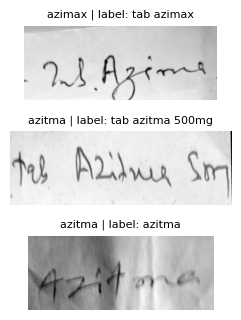

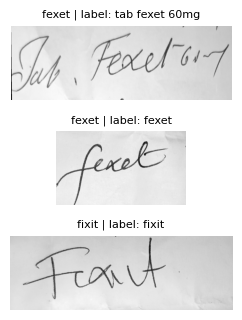

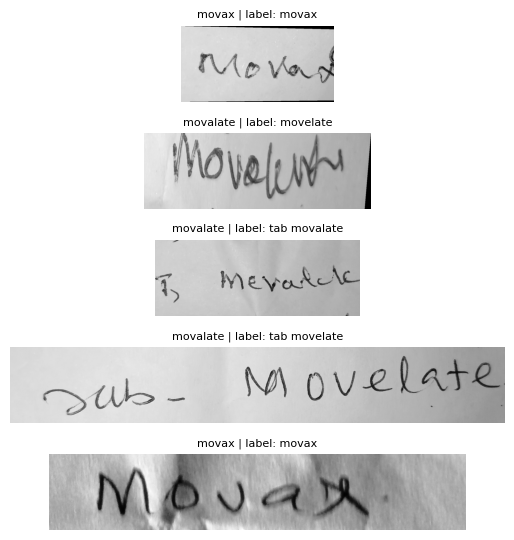

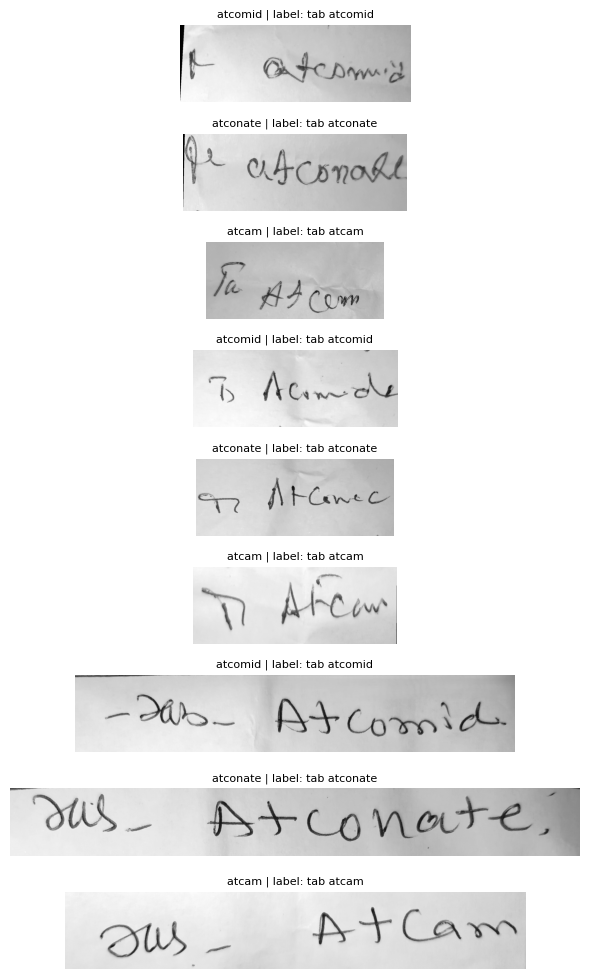

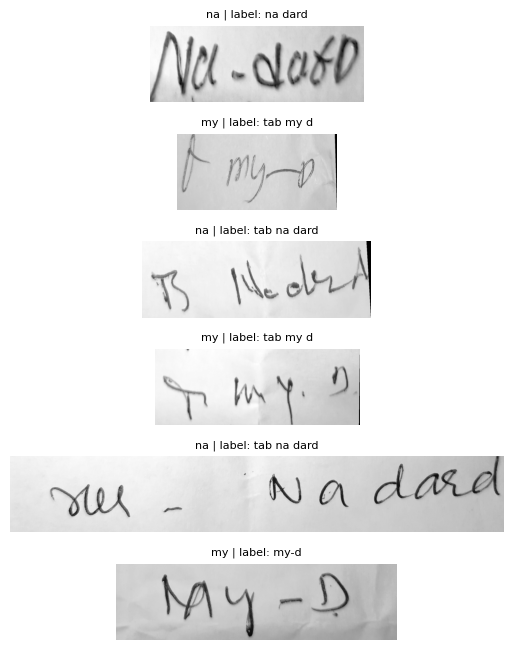

In [ ]:
# Eyeball uncertain groups / Cell 43b
import matplotlib.pyplot as plt
print(df[df["group"] == "na"][["label", "name"]].to_string())
for gs in [("azimax", "azitma"), ("fexet", "fixit"), ("movax", "movalate", "movelate"),
           ("atcam", "atcomid", "atconate"), ("my", "nodard")]:
    sub = df[df["group"].isin(gs)]
    fig, axes = plt.subplots(len(sub), 1, figsize=(6, 1.1 * len(sub)))
    for ax, (_, r) in zip(np.atleast_1d(axes), sub.iterrows()):
        ax.imshow(Image.open(r["path"]).convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f'{r["group"]} | label: {r["label"]}', fontsize=8)
    plt.tight_layout(); plt.show()

In [ ]:
# Build app vocab / Cell 44
allowed = set(opt.character)
alias = {k.title() for k in MERGE if k != "my-d"}   # misspelling variants; "my-d" is the real name behind group "my"
extra = {ln.strip() for ln in Path(r"D:\Projects\MediLens\app\vocab_additions.txt").read_text(encoding="utf-8").splitlines() if ln.strip()}
app_names = sorted({n for n in (set(train_names) | set(new_names) | set(gen) | extra)
                    if 2 <= len(n) <= 30 and set(n) <= allowed and n not in alias})
APP_VOCAB = Path(r"D:\Projects\MediLens\app\vocab.txt")
APP_VOCAB.write_text("\n".join(app_names), encoding="utf-8")
print(len(app_names), "names written to", APP_VOCAB)

for probe in ["Atcomid", "Atconate", "Tonoflex", "Azimax", "Azitona", "Tonoflox", "Nodard"]:
    print(probe, "->", "in vocab" if probe in app_names else "NOT in vocab")

704 names written to D:\Projects\MediLens\app\vocab.txt
Atcomid -> in vocab
Atconate -> in vocab
Tonoflex -> NOT in vocab
Azimax -> in vocab
Azitona -> NOT in vocab
Tonoflox -> in vocab
Nodard -> in vocab


In [18]:
# Out-of-fold evaluation vs no fine-tuning / Cell 45
prep = make_prep("gray")
Mk = np.zeros_like(M)
for k in range(5):
    rows = np.where(df["fold"].values == k)[0]
    m = load_ft(f"kaggle_e400_f{k}")
    Mk[rows] = nll_matrix(m, [paths[i] for i in rows], vocab_list)
    del m; gc.collect(); torch.cuda.empty_cache()
np.save(WORK / "kaggle_e400_oof_nll.npy", Mk)

def gkey(n):                       # vocab entry -> drug key, same rule as df["group"]
    t = strip(n).lower().split()[0]
    return MERGE.get(t, t)
vg = [gkey(n) for n in names]

def topk_hits(S, ks=(1, 3, 5)):    # dedupes Tab/Cap variants so they don't eat slots
    truth_g = df["group"].values
    out = {k: np.zeros(len(df), bool) for k in ks}
    for i in range(len(df)):
        seen = []
        for j in np.argsort(S[i]):
            if vg[j] not in seen:
                seen.append(vg[j])
            if len(seen) == max(ks):
                break
        for k in ks:
            out[k][i] = truth_g[i] in seen[:k]
    return out

base_h = topk_hits(M / lens[None, :])      # no fine-tuning (same recipe as Cell 42)
ft_h   = topk_hits(Mk / lens[None, :])     # out-of-fold fine-tuned

# cluster bootstrap over drugs (images of one drug are not independent)
rng = np.random.default_rng(0)
G = [np.where(df["group"].values == g)[0] for g in df["group"].unique()]
boots = [np.concatenate([G[j] for j in rng.integers(0, len(G), len(G))]) for _ in range(2000)]
tab = []
for k in (1, 3, 5):
    b, f = base_h[k], ft_h[k]
    d = np.array([f[ix].mean() - b[ix].mean() for ix in boots]) * 100
    tab.append({"top-k": k, "no fine-tune %": round(b.mean() * 100, 1),
                "fold fine-tune %": round(f.mean() * 100, 1),
                "gain (pts)": round((f.mean() - b.mean()) * 100, 1),
                "95% CI of gain": f"[{np.percentile(d, 2.5):.1f}, {np.percentile(d, 97.5):.1f}]"})
print(pd.DataFrame(tab).to_string(index=False))
print(df.assign(hit=ft_h[1]).groupby("fold")["hit"].mean().round(3))

No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
 top-k  no fine-tune %  fold fine-tune %  gain (pts) 95% CI of gain
     1            52.9              60.9         8.0   [-1.1, 16.5]
     3            66.7              73.6         6.9    [0.0, 14.0]
     5            74.7              78.2         3.4   [-3.8, 10.8]
fold
0    0.556
1    0.611
2    0.529
3    0.588
4    0.765
Name: hit, dtype: float64


In [21]:
# Fixed vs broken images and per-fold rates / Cell 46
for k_ in (1, 3):
    b, f = base_h[k_], ft_h[k_]
    print(f"top-{k_}: fixed {int((~b & f).sum())} | broken {int((b & ~f).sum())}")
print(pd.DataFrame({"fold": df["fold"], "base top-1": base_h[1], "ft top-1": ft_h[1],
                    "base top-3": base_h[3], "ft top-3": ft_h[3]})
        .groupby("fold").mean().mul(100).round(1))

top-1: fixed 11 | broken 4
top-3: fixed 10 | broken 4
      base top-1  ft top-1  base top-3  ft top-3
fold                                            
0           44.4      55.6        61.1      66.7
1           55.6      61.1        72.2      88.9
2           52.9      52.9        52.9      52.9
3           47.1      58.8        76.5      70.6
4           64.7      76.5        70.6      88.2


In [19]:
# OOF flag-threshold sweep / Cell 47
prep = make_prep("gray")

# raw greedy reads from each image's own out-of-fold model
raw_oof = [None] * len(df)
for k in range(5):
    rows = np.where(df["fold"].values == k)[0]
    m = load_ft(f"kaggle_e400_f{k}")
    with torch.no_grad():
        for i in range(0, len(rows), 32):
            ix = rows[i:i + 32]
            x = torch.stack([prep(paths[j]) for j in ix]).to(device)
            out = m(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
            for j, r in zip(ix, greedy(out, ft_converter.character)):
                raw_oof[j] = r
    del m; gc.collect(); torch.cuda.empty_cache()

# vocabulary pick (same scoring as Cell 45) and whether it is the right drug
Sk = Mk / lens[None, :]
best = Sk.argmin(1)
correct = np.array([gkey(names[j]) == g for j, g in zip(best, df["group"].values)])
print("top-1 check (should match Cell 45, ~0.609):", round(correct.mean(), 3))

# disagreement = raw read vs vocabulary pick, prefix and dose removed from both
dis = np.array([edit_distance(norm(r), norm(names[j])) / max(len(norm(names[j])), 1)
                for r, j in zip(raw_oof, best)])

sweep_rows = []
for th in np.round(np.arange(0.1, 1.01, 0.05), 2):
    keep = dis <= th
    sweep_rows.append({
        "threshold": th,
        "flagged %": round(100 * (~keep).mean(), 1),
        "accuracy on accepted %": round(100 * correct[keep].mean(), 1) if keep.any() else np.nan,
        "wrong reads caught %": round(100 * (~keep & ~correct).sum() / max((~correct).sum(), 1), 1),
        "correct reads flagged %": round(100 * (~keep & correct).sum() / max(correct.sum(), 1), 1)})
sweep_oof = pd.DataFrame(sweep_rows)
print(sweep_oof.to_string(index=False))
sweep_oof.to_csv(RESULTS / "results_flag_sweep_oof.csv", index=False)

# --- margin signal: gap between the best drug and the best *different* drug (Tab/Cap variants collapsed via vg) ---
vg_arr = np.array(vg)
margin = np.zeros(len(df))
for i in range(len(df)):
    order = np.argsort(Sk[i])
    nxt = next(j for j in order if vg_arr[j] != vg_arr[order[0]])
    margin[i] = Sk[i, nxt] - Sk[i, order[0]]

def auroc(score, ok):    # chance that a right read scores higher than a wrong one; 0.5 = no signal
    a, b = score[ok], score[~ok]
    return (a[:, None] > b[None, :]).mean() + 0.5 * (a[:, None] == b[None, :]).mean()

print("AUROC, -disagreement:", round(auroc(-dis, correct), 3))
print("AUROC, margin:       ", round(auroc(margin, correct), 3))

mrows = []
for q in (0.3, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9):
    keep = margin >= np.quantile(margin, q)
    mrows.append({"margin flagged %": round(100 * (~keep).mean(), 1),
                  "accepted": int(keep.sum()),
                  "wrong accepted": int((keep & ~correct).sum()),
                  "correct flagged %": round(100 * (~keep & correct).sum() / correct.sum(), 1)})
print(pd.DataFrame(mrows).to_string(index=False))

# --- absolute margin cut-offs, and a drug-level bootstrap of the AUROC gap ---
for q in (0.5, 0.6, 0.7, 0.75):
    print(f"margin cut-off at {int(q * 100)}% flagged: {np.quantile(margin, q):.4f}")

gap = []
for ix in boots:                       # drug-level resamples defined in Cell 45
    ok = correct[ix]
    if ok.all() or (~ok).all():
        continue
    gap.append(auroc(margin[ix], ok) - auroc(-dis[ix], ok))
print("AUROC gain of margin over disagreement: %.3f, 95%% CI [%.3f, %.3f]" % (
    np.mean(gap), *np.percentile(gap, [2.5, 97.5])))

No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
top-1 check (should match Cell 45, ~0.609): 0.609
 threshold  flagged %  accuracy on accepted %  wrong reads caught %  correct reads flagged %
      0.10       90.8                   100.0                 100.0                     84.9
      0.15       86.2                   100.0                 100.0                     77.4
      0.20       82.8                   100.0                 100.0                     71.7
      0.25       81.6                   100.0                 100.0                     69.8
      0.30       81.6                   100.0                 100.0                     69.8
      0.35       78.2                   100.0                 100.0                     64.2
      0.40       75.9                   100.0                 100.0                     60.4
      0.45       74.7          

In [20]:
# Min-length and disagreement veto / Cell 47b
def veto_grid(raw_len, dis, margin, correct, thr=2.30,
              lens=(0, 3, 4, 5), dmaxs=(9.0, 0.8, 0.6, 0.5, 0.4)):
    rows = []
    for L in lens:
        for D in dmaxs:
            acc = (margin >= thr) & (raw_len >= L) & (dis <= D)
            rows.append({"min raw length": L, "max disagreement": "off" if D >= 9 else D,
                         "accepted": int(acc.sum()), "wrong accepted": int((acc & ~correct).sum()),
                         "correct accepted": int((acc & correct).sum())})
    return pd.DataFrame(rows)

raw_len  = np.array([len(norm(r)) for r in raw_oof])
name_len = np.array([len(norm(names[j])) for j in best])
print(veto_grid(raw_len, dis, margin, correct).to_string(index=False))
print("accepted reads whose matched name has < 3 letters:", int(((margin >= 2.30) & (name_len < 3)).sum()))

 min raw length max disagreement  accepted  wrong accepted  correct accepted
              0              off        27               0                27
              0              0.8        22               0                22
              0              0.6        18               0                18
              0              0.5        18               0                18
              0              0.4        15               0                15
              3              off        27               0                27
              3              0.8        22               0                22
              3              0.6        18               0                18
              3              0.5        18               0                18
              3              0.4        15               0                15
              4              off        26               0                26
              4              0.8        21               0                21

In [18]:
# Dosage digit-read test (out-of-fold) / Cell 48
import sys, importlib
sys.path.insert(0, r"D:\Projects\MediLens\app")
import prescription_parser as pp; importlib.reload(pp)

lab = [pp.parse_line(l) for l in df["label"]]          # dose written in the label
red = [pp.parse_line(r) for r in raw_oof]              # dose recovered from the out-of-fold raw read

key = lambda x: None if x["dosage"] is None else (tuple(x["dosage"]["values"]), x["dosage"]["unit"])
has = np.array([x["dosage"] is not None for x in lab])            # images whose label has a dose
found = np.array([x["dosage"] is not None for x in red])
exact = np.array([key(a) == key(b) for a, b in zip(lab, red)])
fixed = np.array([bool(x["digit_fixes"]) for x in red])

print(f"images with a dose in the label: {has.sum()} of {len(df)}")
print(f"dose found in the read:          {(has & found).sum()} / {has.sum()}")
print(f"dose exactly right (values+unit): {(has & exact).sum()} / {has.sum()}")
print(f"reads where digit repair fired:   {fixed.sum()}")
print(f"false doses on images with none:  {(~has & found).sum()} / {(~has).sum()}")

miss = pd.DataFrame({"label": df["label"], "raw": raw_oof,
                     "label_dose": [key(x) for x in lab], "read_dose": [key(x) for x in red]})[has & ~exact]
print(miss.to_string(index=False))

images with a dose in the label: 14 of 87
dose found in the read:          6 / 14
dose exactly right (values+unit): 0 / 14
reads where digit repair fired:   0
false doses on images with none:  0 / 73
            label              raw    label_dose      read_dose
     cefiget 40mg        Teteti0mg   ((40,), mg)     ((0,), mg)
 tab azitma 500mg  Teb Azilus Simt  ((500,), mg)           None
   tab nims 100mg   Tabb Nimib iig  ((100,), mg)           None
 cap caricef 40mg       Lmga Caryr   ((40,), mg)           None
   tab getryl 1mg  Tan Oetemg C0mg    ((1,), mg)     ((0,), mg)
 tab covam 5-80mg    Tab BonamlagE ((5, 80), mg)           None
   tab fexet 60mg laib Peoceti10mg   ((60,), mg)    ((10,), mg)
       starcox 90            ilodx ((90,), None)           None
     leflox 200mg       Kefes 10mg  ((200,), mg)    ((10,), mg)
     cefiget 40mg        TOetget0g   ((40,), mg)      ((0,), g)
 tab lipiget 10mg   Ta ifiylet 107   ((10,), mg) ((107,), None)
   cap risek 20mg  Cin Leisrta x

In [21]:
# Closed-set dose scoring on hand-cropped dose regions (out-of-fold) / Cell 49
import sys, importlib
from pathlib import Path
sys.path.insert(0, r"D:\Projects\MediLens\app")
import prescription_parser as pp; importlib.reload(pp)

# ---------------- EDIT THESE ----------------
DOSE_DIR  = Path(r"D:\Projects\MediLens\Data\dose_crops")   # one tight crop of the dose text per image, named <original filename stem>.png
STRENGTHS = ["0.5", "1", "2", "2.5", "5", "10", "15", "20", "25", "30", "40", "50", "60", "75", "80", "90",
             "100", "120", "150", "200", "250", "300", "400", "500", "625", "650", "750", "1000",
             "5/80", "5/160", "10/80", "10/160", "500/125", "625/125"]
# --------------------------------------------
# Unit is assumed to be mg; candidates are compared on the strength value only.

DOSE_DIR.mkdir(parents=True, exist_ok=True)
lab = [pp.parse_line(l) for l in df["label"]]
truth_val = [None if x["dosage"] is None else tuple(x["dosage"]["values"]) for x in lab]
has = np.array([t is not None for t in truth_val])

def to_vals(s):
    return tuple(int(float(v)) if float(v).is_integer() else float(v) for v in s.split("/"))

# every strength written three ways: "40mg", "40 mg", "40"
cand_text, cand_val = [], []
for s in STRENGTHS:
    for surf in (f"{s}mg", f"{s} mg", s):
        cand_text.append(surf); cand_val.append(to_vals(s))
uvals = sorted(set(cand_val), key=lambda v: (len(v), v))
col = {v: [j for j, cv in enumerate(cand_val) if cv == v] for v in uvals}

# how many true doses are even in the list (accuracy cannot exceed this)
need = {truth_val[i] for i in np.where(has)[0]}
print(f"{len(need)} distinct true strengths | missing from STRENGTHS: {sorted(need - set(uvals))}")

# which crops exist yet
def find_crop(i):
    stem = Path(df["filename"].iloc[i]).stem
    for ext in (".png", ".jpg", ".jpeg"):
        p = DOSE_DIR / (stem + ext)
        if p.exists():
            return str(p)
    return None

idx = list(np.where(has)[0])
ready = [i for i in idx if find_crop(i)]
todo = [i for i in idx if i not in ready]
print(f"crops found: {len(ready)} / {len(idx)} in {DOSE_DIR}")
if todo:
    print("still to crop (save as <stem>.png):")
    for i in todo:
        print("  ", df["filename"].iloc[i], "|", df["label"].iloc[i])
assert ready, "put at least one dose crop in DOSE_DIR, then rerun"

# score each crop with the model that never saw its drug (out-of-fold), length-normalised
prep = make_prep("gray")
lens_c = np.array([len(t) for t in cand_text], dtype=np.float32)
S = np.zeros((len(ready), len(cand_text)), dtype=np.float32)
folds = df["fold"].values
for k in range(5):
    rows = [r for r, i in enumerate(ready) if folds[i] == k]
    if not rows:
        continue
    m = load_ft(f"kaggle_e400_f{k}")
    S[rows] = nll_matrix(m, [find_crop(ready[r]) for r in rows], cand_text) / lens_c[None, :]
    del m; gc.collect(); torch.cuda.empty_cache()

P = np.stack([S[:, col[v]].min(1) for v in uvals], axis=1)     # best score per strength value
order = np.argsort(P, axis=1)
out = []
for r, i in enumerate(ready):
    ranked = [uvals[j] for j in order[r]]
    t = truth_val[i]
    out.append({"file": df["filename"].iloc[i], "label": df["label"].iloc[i], "truth": t,
                "pick": ranked[0], "top3": ranked[:3],
                "margin": round(float(P[r, order[r, 1]] - P[r, order[r, 0]]), 3),
                "top1": ranked[0] == t, "top3_hit": t in ranked[:3]})
dose_res = pd.DataFrame(out)
n = len(dose_res)
print(f"\nn = {n} | candidate strengths = {len(uvals)} | chance top-1 = {100 / len(uvals):.1f}%")
print(f"top-1: {dose_res['top1'].sum()} / {n} | top-3: {dose_res['top3_hit'].sum()} / {n}")
print("(same-line free read, Cell 48: 0 / 14 exact)")
print(dose_res.to_string(index=False))
print("\nmean margin | right picks: %.3f | wrong picks: %.3f" % (
    dose_res.loc[dose_res["top1"], "margin"].mean() if dose_res["top1"].any() else float("nan"),
    dose_res.loc[~dose_res["top1"], "margin"].mean() if (~dose_res["top1"]).any() else float("nan")))
dose_res.to_csv(RESULTS / "results_dose_closed_set.csv", index=False)

10 distinct true strengths | missing from STRENGTHS: []
crops found: 13 / 14 in D:\Projects\MediLens\Data\dose_crops
still to crop (save as <stem>.png):
   IMG_20241006_144119 - Copy.jpg | tab azitma 500mg
No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified

n = 13 | candidate strengths = 34 | chance top-1 = 2.9%
top-1: 2 / 13 | top-3: 4 / 13
(same-line free read, Cell 48: 0 / 14 exact)
                                                  file             label   truth   pick                    top3  margin  top1  top3_hit
.trashed-1730802496-IMG_20241006_151957 - Copy (2).jpg      cefiget 40mg   (40,)  (90,) [(90,), (200,), (120,)]   1.391 False     False
                        IMG_20241006_144408 - Copy.jpg    tab nims 100mg  (100,)   (1,)     [(1,), (2,), (10,)]   1.446 False     False
                               IMG_20241006_144753.jpg  cap caricef 40mg   (40,

In [20]:
for i in np.where(has)[0]:
    print(df["filename"].iloc[i], "|", df["label"].iloc[i], "|", df["path"].iloc[i])

.trashed-1730802496-IMG_20241006_151957 - Copy (2).jpg | cefiget 40mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\.trashed-1730802496-IMG_20241006_151957 - Copy (2).jpg
IMG_20241006_144119 - Copy.jpg | tab azitma 500mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_144119 - Copy.jpg
IMG_20241006_144408 - Copy.jpg | tab nims 100mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_144408 - Copy.jpg
IMG_20241006_144753.jpg | cap caricef 40mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_144753.jpg
IMG_20241006_151556.jpg | tab getryl 1mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_151556.jpg
IMG_20241006_151638.jpg | tab covam 5-80mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_151638.jpg
IMG_20241006_151719.jpg | tab fexet 60mg | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_151719.jpg
IMG_20241006_151807.jpg | starcox 90 | D:\Projects\MediLens\Data\kaggle_doctor_hw\IMG_20241006_151807.jpg
IMG_20241006_151901.jpg | lefl

In [6]:
# EXIF check on the Kaggle crops / scratch cell (03_external_data)
IMG_DIR = Path(r"D:\Projects\MediLens\Data\kaggle_doctor_hw")
paths = [str(p) for p in IMG_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
rot = {p: Image.open(p).getexif().get(274, 1) for p in paths}
rot = {p: o for p, o in rot.items() if o != 1}
print(len(rot), "of", len(paths), "Kaggle images carry an EXIF orientation tag |", pd.Series(rot).value_counts().to_dict())

0 of 89 Kaggle images carry an EXIF orientation tag | {}
